# Lab Exercise 5 — SARIMA Forecasting (AirPassengers)
Run cells top to bottom.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_absolute_error, mean_squared_error

def metrics(actual, pred):
    return mean_absolute_error(actual, pred), np.sqrt(mean_squared_error(actual, pred))

def fit_sarima(train, order, seasonal):
    return SARIMAX(train, order=order, seasonal_order=seasonal,
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

## 1. Load data and Figure 6 (series + decomposition)

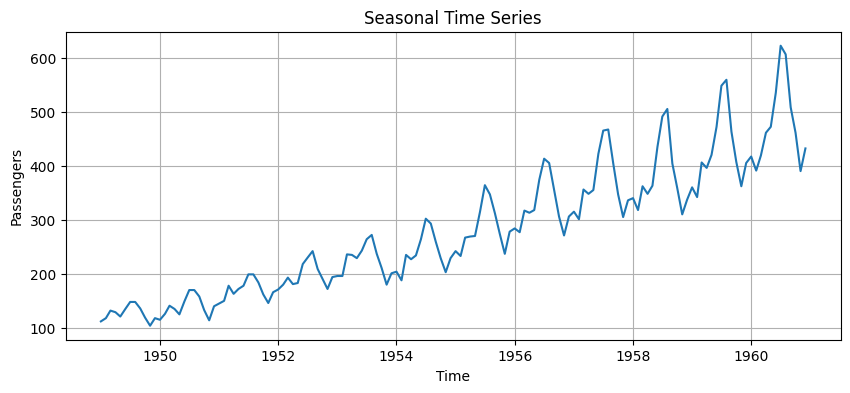

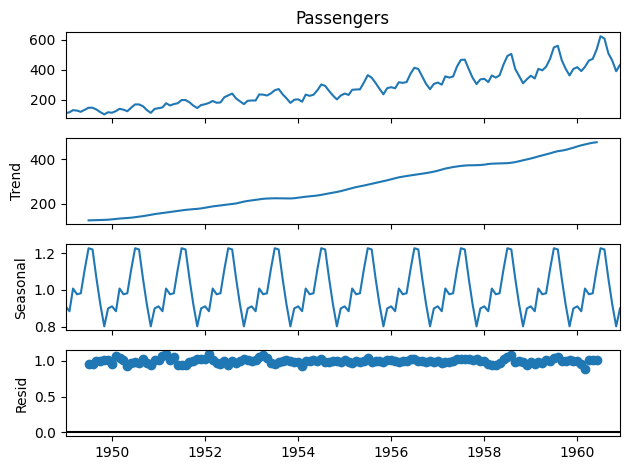

In [2]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url, parse_dates=["Month"], index_col="Month")
series = df["Passengers"].astype(float).asfreq("MS")

plt.figure(figsize=(10, 4)); plt.plot(series)
plt.title("Seasonal Time Series"); plt.xlabel("Time"); plt.ylabel("Passengers"); plt.grid(); plt.show()
seasonal_decompose(series, model="multiplicative", period=12).plot(); plt.show()

## 2. Figure 7 (seasonal difference) and Figure 8 (ACF / PACF)

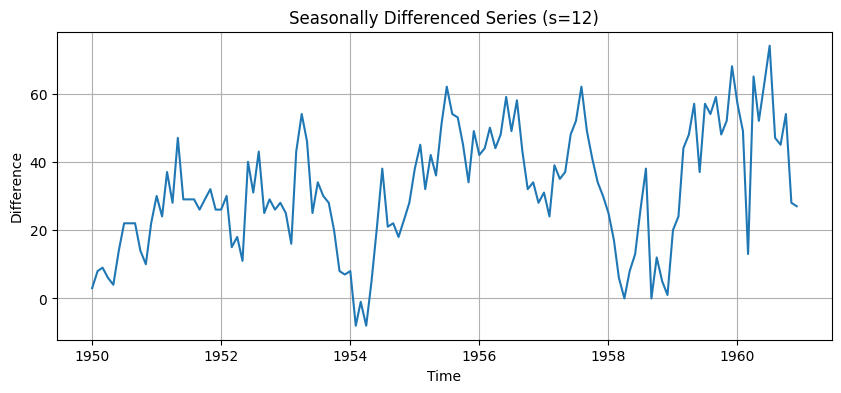

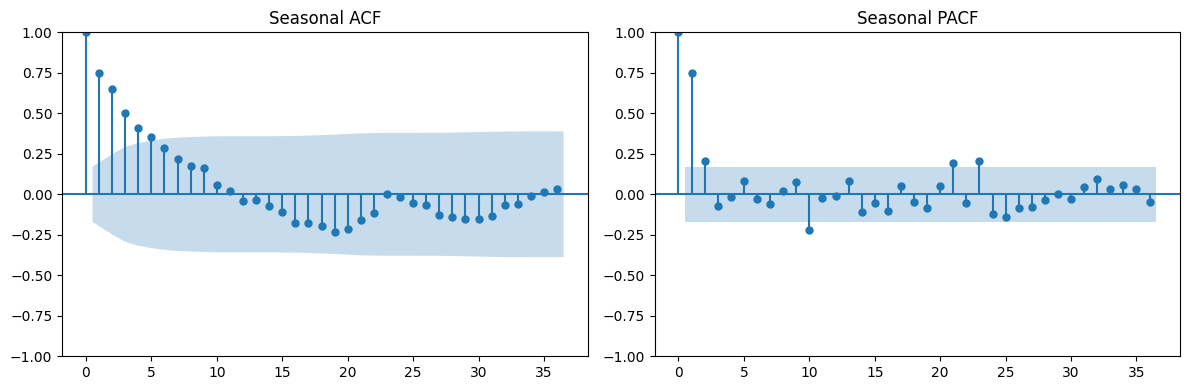

In [3]:
seasonal_diff = series.diff(12).dropna()
plt.figure(figsize=(10, 4)); plt.plot(seasonal_diff)
plt.title("Seasonally Differenced Series (s=12)"); plt.xlabel("Time"); plt.ylabel("Difference"); plt.grid(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(seasonal_diff, ax=ax[0], lags=36); plot_pacf(seasonal_diff, ax=ax[1], lags=36, method="ywm")
ax[0].set_title("Seasonal ACF"); ax[1].set_title("Seasonal PACF"); plt.tight_layout(); plt.show()

## 3. Split, fit SARIMA(1,1,1)(1,1,1,12), Figure 9 (forecast)

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Fri, 30 Oct 2026   AIC                            657.601
Time:                                    10:32:42   BIC                            669.988
Sample:                                01-01-1949   HQIC                           662.592
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.461      0.000      -1.184      -0.461
ma.L1          0.7176      0.224   

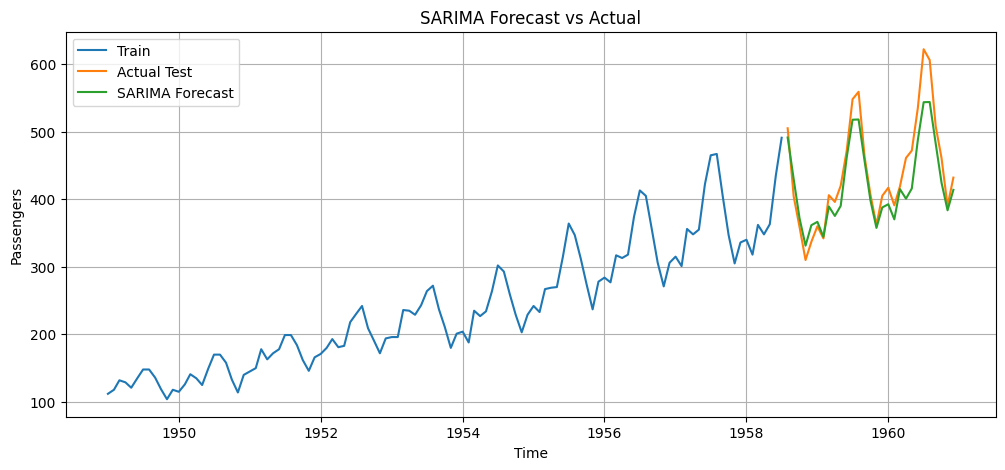

In [4]:
train_size = int(len(series) * 0.80)
train, test = series.iloc[:train_size], series.iloc[train_size:]

model_fit = fit_sarima(train, (1,1,1), (1,1,1,12))
print(model_fit.summary())

forecast = model_fit.forecast(steps=len(test))
mae, rmse = metrics(test, forecast)
print(f"(p,d,q)=(1,1,1)  (P,D,Q,s)=(1,1,1,12)   MAE={mae:.2f}   RMSE={rmse:.2f}")

plt.figure(figsize=(12, 5))
plt.plot(train, label="Train"); plt.plot(test, label="Actual Test"); plt.plot(test.index, forecast, label="SARIMA Forecast")
plt.title("SARIMA Forecast vs Actual"); plt.xlabel("Time"); plt.ylabel("Passengers"); plt.legend(); plt.grid(); plt.show()

## 4. Figure 10 (residuals)
Change from the handout: the first 13 residuals (d + D·s burn-in) are dropped; they are artificially huge.

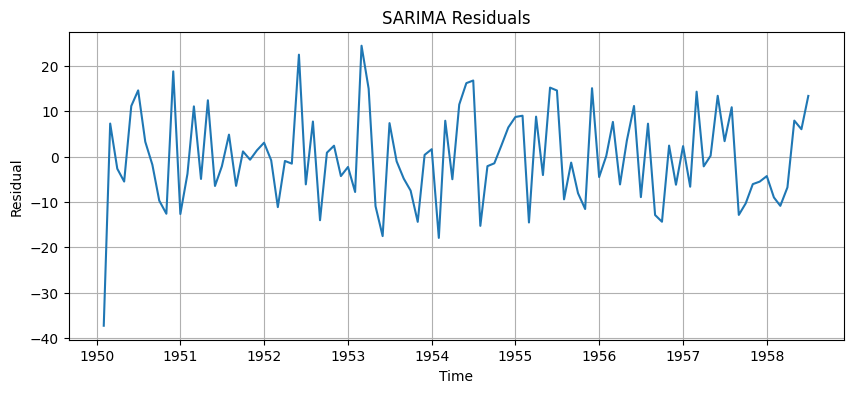

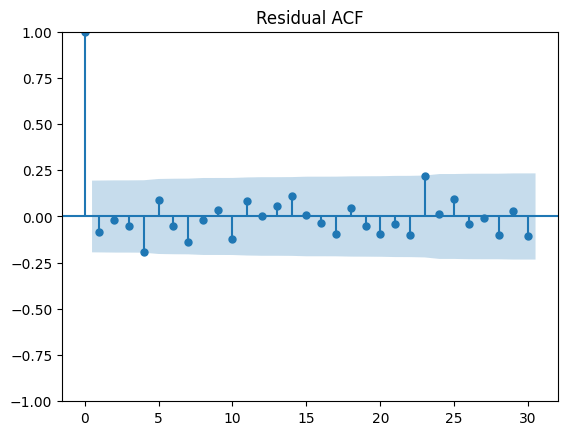

      lb_stat  lb_pvalue
12  11.081406   0.521955
24  24.169701   0.451928


In [5]:
resid = model_fit.resid.iloc[13:]
plt.figure(figsize=(10, 4)); plt.plot(resid)
plt.title("SARIMA Residuals"); plt.xlabel("Time"); plt.ylabel("Residual"); plt.grid(); plt.show()
plot_acf(resid, lags=30); plt.title("Residual ACF"); plt.show()
print(acorr_ljungbox(resid, lags=[12, 24]))

## Task 5.1 — Compare SARIMA configurations (same split)

In [6]:
configs = [((1,1,1),(1,1,1,12)), ((0,1,1),(0,1,1,12)), ((2,1,1),(0,1,1,12)), ((1,1,0),(1,1,0,12))]
rows, fcs = [], {}
for o, so in configs:
    f = fit_sarima(train, o, so); fc = f.forecast(len(test)); m, r = metrics(test, fc)
    rows.append([o, so, f.aic, m, r]); fcs[(o, so)] = fc
table = pd.DataFrame(rows, columns=["order", "seasonal", "AIC", "MAE", "RMSE"]).round(2); table

,order,seasonal,AIC,MAE,RMSE
0,"(1, 1, 1)","(1, 1, 1, 12)",657.60,25.27,31.79
1,"(0, 1, 1)","(0, 1, 1, 12)",659.34,24.06,30.58
2,"(2, 1, 1)","(0, 1, 1, 12)",661.13,22.43,28.99
3,"(1, 1, 0)","(1, 1, 0, 12)",666.51,23.90,30.43


## Task 5.2 — Why s = 12
- **s=12:** monthly data, the pattern repeats every 12 observations (one year) — e.g. peak every July/August in AirPassengers.
- **s=7:** daily data with weekly pattern — e.g. daily restaurant footfall / website traffic (weekend peak).
- **s=24:** hourly data with daily pattern — e.g. hourly electricity demand.
- s must equal the number of observations in one full cycle, and should be confirmed by ACF spikes at lags s, 2s, 3s, not assumed.

## Task 5.3 — ARIMA vs SARIMA on the same test set

ARIMA   MAE=63.55  RMSE=82.51
SARIMA  MAE=25.27  RMSE=31.79


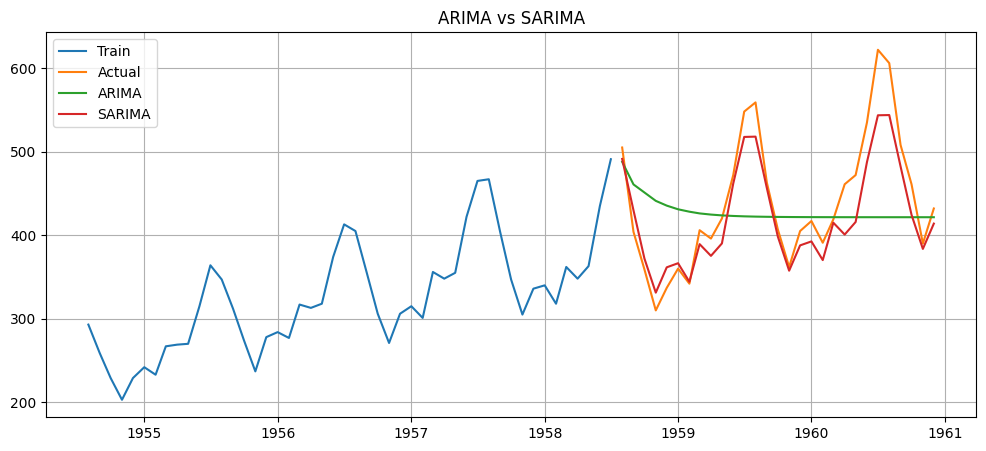

In [7]:
best_arima_order = (2, 1, 2)   # <- replace with the best order from your Task 4.1 table
arima_fc = ARIMA(train, order=best_arima_order).fit().forecast(len(test))
sarima_fc = fcs[configs[0]]    # SARIMA(1,1,1)(1,1,1,12); change index to use your best config

for name, fc in [("ARIMA", arima_fc), ("SARIMA", sarima_fc)]:
    m, r = metrics(test, fc); print(f"{name:7s} MAE={m:.2f}  RMSE={r:.2f}")

plt.figure(figsize=(12, 5)); plt.plot(train.iloc[-48:], label="Train"); plt.plot(test, label="Actual")
plt.plot(test.index, arima_fc, label="ARIMA"); plt.plot(test.index, sarima_fc, label="SARIMA")
plt.title("ARIMA vs SARIMA"); plt.legend(); plt.grid(); plt.show()

## Task 5.4 — Seasonal differencing: D=0 vs D=1

D=0: AIC=721.7  MAE=18.70  RMSE=22.40
D=1: AIC=657.6  MAE=25.27  RMSE=31.79


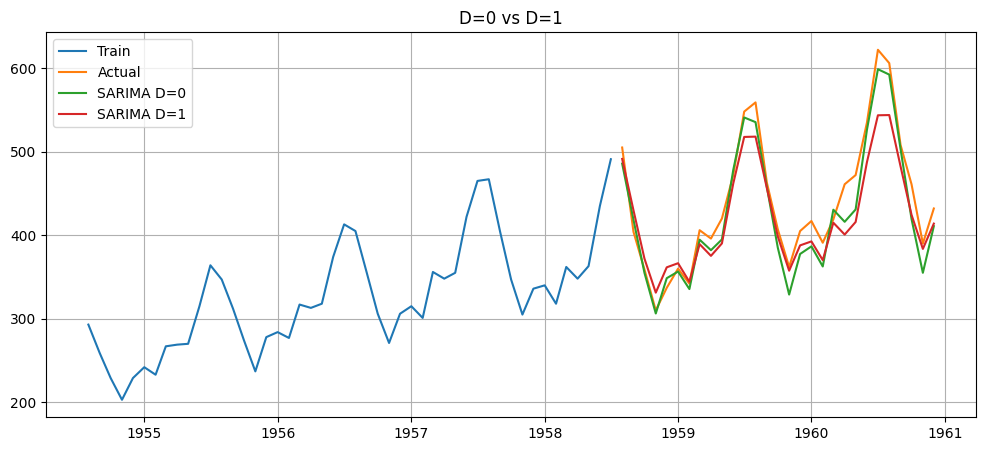

In [8]:
plt.figure(figsize=(12, 5)); plt.plot(train.iloc[-48:], label="Train"); plt.plot(test, label="Actual")
for D in [0, 1]:
    f = fit_sarima(train, (1,1,1), (1,D,1,12)); fc = f.forecast(len(test)); m, r = metrics(test, fc)
    print(f"D={D}: AIC={f.aic:.1f}  MAE={m:.2f}  RMSE={r:.2f}")
    plt.plot(test.index, fc, label=f"SARIMA D={D}")
plt.title("D=0 vs D=1"); plt.legend(); plt.grid(); plt.show()

## Task 5.5 — Different seasonal dataset: Monthly Car Sales in Quebec, 1960–1968
Source: https://github.com/jbrownlee/Datasets (monthly-car-sales.csv). Monthly data → s = 12 (checked via ACF below).

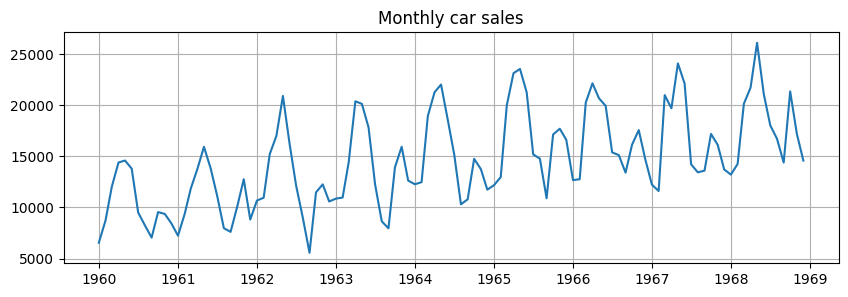

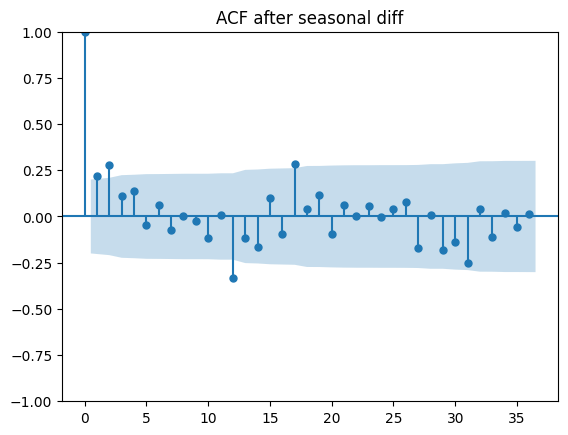

train: 86 test: 22
SARIMA(1,1,1)(1,1,1,12)  MAE=1500.94  RMSE=1820.59


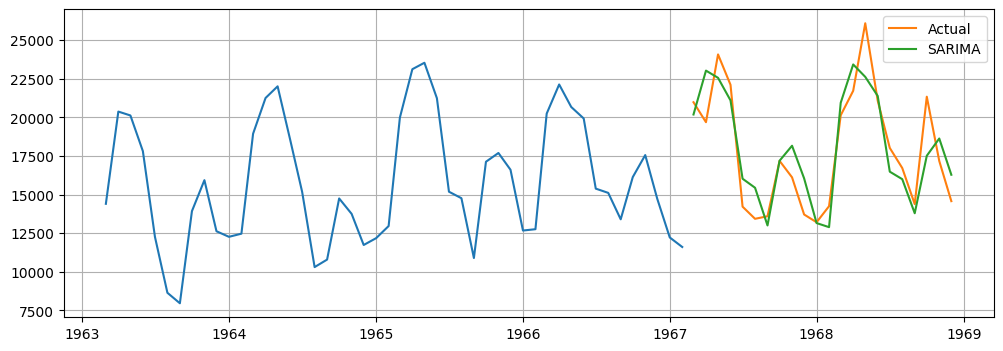

In [9]:
url2 = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/monthly-car-sales.csv"
s2 = pd.read_csv(url2, parse_dates=["Month"], index_col="Month").iloc[:, 0].astype(float).asfreq("MS")
plt.figure(figsize=(10, 3)); plt.plot(s2); plt.title("Monthly car sales"); plt.grid(); plt.show()
plot_acf(s2.diff(12).dropna(), lags=36); plt.title("ACF after seasonal diff"); plt.show()

n = int(len(s2) * 0.8); tr2, te2 = s2.iloc[:n], s2.iloc[n:]
print("train:", len(tr2), "test:", len(te2))
f = fit_sarima(tr2, (1,1,1), (1,1,1,12)); fc = f.forecast(len(te2))
print("SARIMA(1,1,1)(1,1,1,12)  MAE=%.2f  RMSE=%.2f" % metrics(te2, fc))
plt.figure(figsize=(12, 4)); plt.plot(tr2.iloc[-48:]); plt.plot(te2, label="Actual"); plt.plot(te2.index, fc, label="SARIMA")
plt.legend(); plt.grid(); plt.show()